In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import KFold, RepeatedKFold, cross_validate, cross_val_predict
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_style("whitegrid")

In [32]:
file_id = "1Ts1Yjt9oiTdOeCeuJPbExNz7N3vmd0Ln"
url = f"https://docs.google.com/spreadsheets/d/{file_id}/export?format=xlsx"

excel_file = pd.ExcelFile(url)

courses = pd.read_excel(excel_file, sheet_name="Courses")
teachers = pd.read_excel(excel_file, sheet_name="Teachers")
transactions = pd.read_excel(excel_file, sheet_name="Transactions")

# Remove accidental spaces from column names
for table in [courses, teachers, transactions]:
    table.columns = table.columns.str.strip()

print("Courses:", courses.shape)
print("Teachers:", teachers.shape)
print("Transactions:", transactions.shape)

Courses: (60, 8)
Teachers: (60, 7)
Transactions: (10000, 7)


In [33]:
print("Missing values in Courses:", courses.isnull().sum().sum())
print("Missing values in Teachers:", teachers.isnull().sum().sum())
print("Missing values in Transactions:", transactions.isnull().sum().sum())

print("Duplicate rows in Courses:", courses.duplicated().sum())
print("Duplicate rows in Teachers:", teachers.duplicated().sum())
print("Duplicate transaction IDs:", transactions["TransactionID"].duplicated().sum())

# Convert the date column to a real date type
transactions["TransactionDate"] = pd.to_datetime(transactions["TransactionDate"])

print("Dates from", transactions["TransactionDate"].min().date(),
      "to", transactions["TransactionDate"].max().date())

Missing values in Courses: 0
Missing values in Teachers: 0
Missing values in Transactions: 0
Duplicate rows in Courses: 0
Duplicate rows in Teachers: 0
Duplicate transaction IDs: 0
Dates from 2025-01-01 to 2025-12-30


In [34]:
totals = transactions.groupby("CourseID").agg(
    TotalEnrollments=("TransactionID", "count"),
    TotalRevenue=("Amount", "sum")
).reset_index()

eda = courses.merge(totals, on="CourseID", how="left")

print(eda["TotalEnrollments"].describe())
print()
print("Free courses:", (eda["CoursePrice"] == 0).sum(), "| Paid courses:", (eda["CoursePrice"] > 0).sum())

count     60.000000
mean     166.666667
std       12.523424
min      140.000000
25%      157.500000
50%      166.000000
75%      174.750000
max      196.000000
Name: TotalEnrollments, dtype: float64

Free courses: 38 | Paid courses: 22


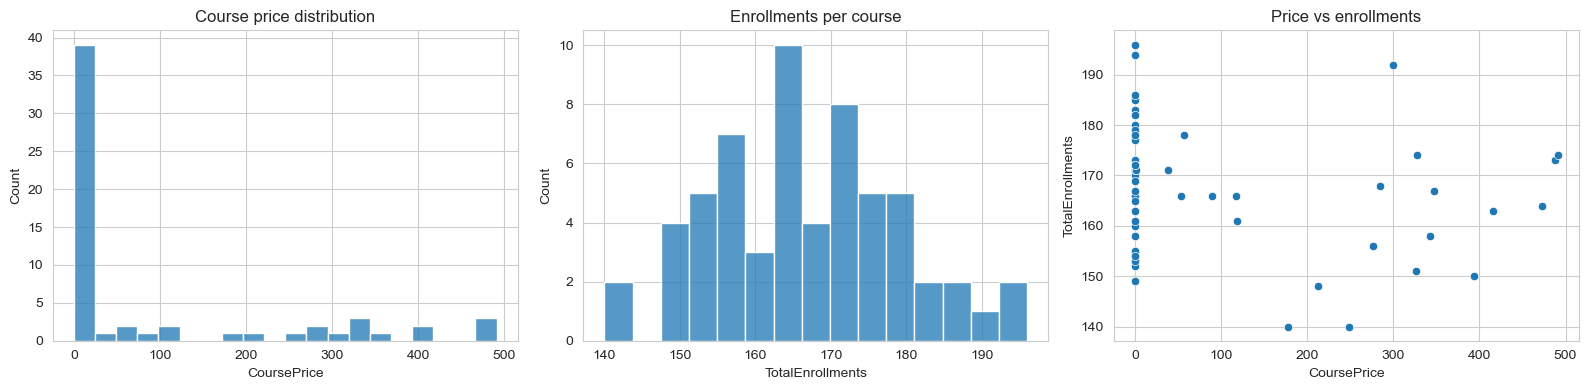

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(eda["CoursePrice"], bins=20, ax=axes[0])
axes[0].set_title("Course price distribution")

sns.histplot(eda["TotalEnrollments"], bins=15, ax=axes[1])
axes[1].set_title("Enrollments per course")

sns.scatterplot(data=eda, x="CoursePrice", y="TotalEnrollments", ax=axes[2])
axes[2].set_title("Price vs enrollments")

plt.tight_layout()
plt.show()

In [36]:
eda["PriceTimesEnrollments"] = eda["CoursePrice"] * eda["TotalEnrollments"]
difference = (eda["TotalRevenue"] - eda["PriceTimesEnrollments"]).abs()

print("Largest difference between revenue and price x enrollments:", round(difference.max(), 2))

Largest difference between revenue and price x enrollments: 0.0


In [37]:
teachers_per_course = transactions.groupby("CourseID")["TeacherID"].nunique()
print(teachers_per_course.describe())

teacher_link_ok = teachers_per_course.max() == 1

if teacher_link_ok:
    print("Each course has one teacher. Teacher features will be used.")
else:
    print("Courses have many different teachers. The link is not reliable, so teacher features will NOT be used.")

count    60.000000
mean     14.783333
std       7.199557
min       7.000000
25%       8.000000
50%      14.000000
75%      20.000000
max      30.000000
Name: TeacherID, dtype: float64
Courses have many different teachers. The link is not reliable, so teacher features will NOT be used.


In [38]:
cutoff_date = pd.Timestamp("2025-07-01")

past = transactions[transactions["TransactionDate"] < cutoff_date]
future = transactions[transactions["TransactionDate"] >= cutoff_date]

past_summary = past.groupby("CourseID").agg(
    PastEnrollments=("TransactionID", "count")
).reset_index()

future_summary = future.groupby("CourseID").agg(
    FutureEnrollments=("TransactionID", "count"),
    FutureRevenue=("Amount", "sum")
).reset_index()

data = courses.merge(past_summary, on="CourseID", how="left")
data = data.merge(future_summary, on="CourseID", how="left")

# A course with no transactions in a period has 0 enrollments
data[["PastEnrollments", "FutureEnrollments", "FutureRevenue"]] = \
    data[["PastEnrollments", "FutureEnrollments", "FutureRevenue"]].fillna(0)

print(data.shape)
data.head()

(60, 11)


,CourseID,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating,PastEnrollments,FutureEnrollments,FutureRevenue
0,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74,79,85,40143.8
1,CR00002,Java Programming,Programming,Free,Intermediate,0.00,37.70,2.43,85,64,0.0
2,CR00003,C++ for Beginners,Programming,Free,Beginner,0.00,19.53,3.85,75,98,0.0
3,CR00004,Advanced Python,Programming,Free,Beginner,0.00,45.13,2.88,71,83,0.0
4,CR00005,Full Stack Development,Programming,Free,Beginner,0.00,28.68,1.28,90,76,0.0


In [39]:
if teacher_link_ok:
    course_teacher = transactions.groupby("CourseID")["TeacherID"].first().reset_index()

    data = data.merge(course_teacher, on="CourseID", how="left")
    data = data.merge(
        teachers[["TeacherID", "Expertise", "YearsOfExperience", "TeacherRating"]],
        on="TeacherID", how="left"
    )

    # 1 if the teacher's expertise is the same as the course category, otherwise 0
    data["ExpertiseMatch"] = (data["Expertise"] == data["CourseCategory"]).astype(int)

data.head()

,CourseID,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating,PastEnrollments,FutureEnrollments,FutureRevenue
0,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74,79,85,40143.8
1,CR00002,Java Programming,Programming,Free,Intermediate,0.00,37.70,2.43,85,64,0.0
2,CR00003,C++ for Beginners,Programming,Free,Beginner,0.00,19.53,3.85,75,98,0.0
3,CR00004,Advanced Python,Programming,Free,Beginner,0.00,45.13,2.88,71,83,0.0
4,CR00005,Full Stack Development,Programming,Free,Beginner,0.00,28.68,1.28,90,76,0.0


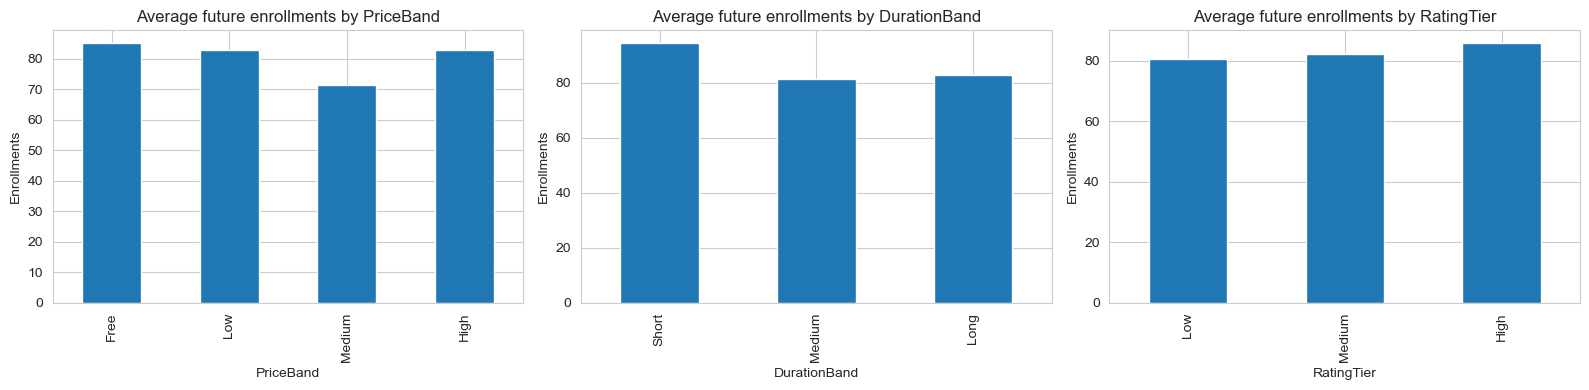

In [40]:
data["PriceBand"] = pd.cut(data["CoursePrice"],
                           bins=[-1, 0, 150, 300, np.inf],
                           labels=["Free", "Low", "Medium", "High"])

data["DurationBand"] = pd.cut(data["CourseDuration"],
                              bins=[0, 5, 20, np.inf],
                              labels=["Short", "Medium", "Long"])

data["RatingTier"] = pd.cut(data["CourseRating"],
                            bins=[0, 2.5, 3.5, 5],
                            labels=["Low", "Medium", "High"])

if teacher_link_ok:
    data["ExperienceBand"] = pd.cut(data["YearsOfExperience"],
                                    bins=[-1, 2, 5, np.inf],
                                    labels=["Junior", "Mid", "Senior"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, band in zip(axes, ["PriceBand", "DurationBand", "RatingTier"]):
    data.groupby(band, observed=True)["FutureEnrollments"].mean().plot(kind="bar", ax=ax)
    ax.set_title("Average future enrollments by " + band)
    ax.set_ylabel("Enrollments")
plt.tight_layout()
plt.show()

In [41]:
numeric_features = ["CoursePrice", "CourseDuration", "CourseRating", "PastEnrollments"]
categorical_features = ["CourseCategory", "CourseLevel"]

if teacher_link_ok:
    numeric_features = numeric_features + ["YearsOfExperience", "TeacherRating", "ExpertiseMatch"]

X = data[numeric_features + categorical_features]
y = data["FutureEnrollments"]

print("Features used:", list(X.columns))
print("Number of courses:", len(X))

Features used: ['CoursePrice', 'CourseDuration', 'CourseRating', 'PastEnrollments', 'CourseCategory', 'CourseLevel']
Number of courses: 60


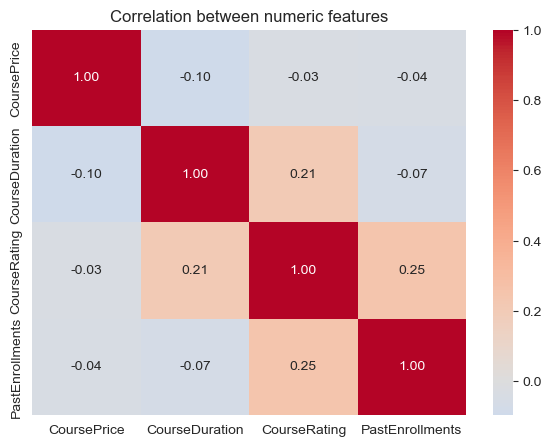

No pair of features has correlation above 0.9.


In [42]:
corr = data[numeric_features].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric features")
plt.show()

# List pairs with correlation above 0.9 (these would be duplicates of each other)
found = False
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.9:
            print("Highly correlated:", corr.columns[i], "and", corr.columns[j])
            found = True
if not found:
    print("No pair of features has correlation above 0.9.")

In [43]:
numeric_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

category_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numbers", numeric_steps, numeric_features),
    ("categories", category_steps, categorical_features)
])

In [44]:
models = {
    "Baseline (always predict average)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10),
    "Lasso Regression": Lasso(alpha=0.1, max_iter=10000),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.05,
                                                   max_depth=2, random_state=42),
}

cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)

rows = []
for name, algorithm in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", algorithm)])

    scores = cross_validate(
        pipe, X, y, cv=cv,
        scoring={"mae": "neg_mean_absolute_error",
                 "rmse": "neg_root_mean_squared_error",
                 "r2": "r2"}
    )

    rows.append({
        "Model": name,
        "MAE": -scores["test_mae"].mean(),
        "RMSE": -scores["test_rmse"].mean(),
        "R2": scores["test_r2"].mean()
    })

results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
results
# Exclude the baseline when selecting a trained model
best_real = results[
    ~results["Model"].str.startswith("Baseline")
].reset_index(drop=True)

best_name = best_real.iloc[0]["Model"]

print("Best trained enrollment model:", best_name)
display(best_real)

Best trained enrollment model: Ridge Regression


,Model,MAE,RMSE,R2
0,Ridge Regression,8.179063,10.363296,-0.248514
1,Lasso Regression,8.976883,11.174419,-0.500210
2,Random Forest,9.044488,10.964787,-0.407376
3,Gradient Boosting,9.340736,11.323247,-0.503908
4,Linear Regression,9.554167,11.861442,-0.731658


Model used: Ridge Regression


,Feature,Importance
2,CourseRating,0.485723
3,PastEnrollments,0.446237
1,CourseDuration,0.182894
5,CourseLevel,0.170871
0,CoursePrice,0.061729
4,CourseCategory,-0.731497


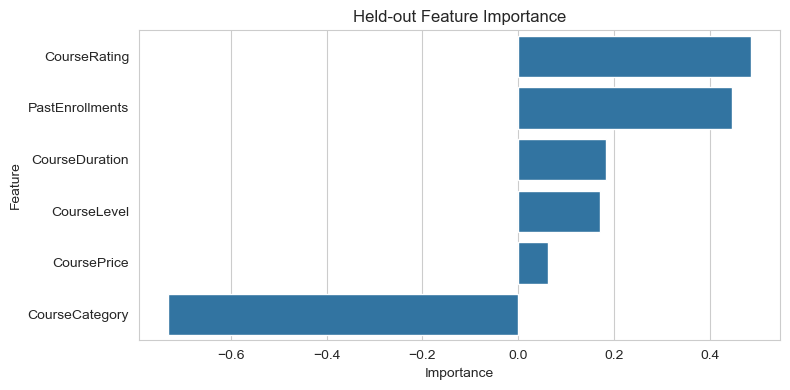

Final enrollment model trained successfully.


In [47]:

from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Select the best trained enrollment model
best_real = results[
    ~results["Model"].str.startswith("Baseline")
].reset_index(drop=True)

if best_real.empty:
    raise ValueError("No trained models found in results.")

best_name = best_real.iloc[0]["Model"]

# Split the data for feature importance
X_imp_train, X_imp_test, y_imp_train, y_imp_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train a separate model
importance_model = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", clone(models[best_name]))
])

importance_model.fit(X_imp_train, y_imp_train)

# Calculate feature importance
perm = permutation_importance(
    importance_model,
    X_imp_test,
    y_imp_test,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False)

print("Model used:", best_name)
display(importance)

plt.figure(figsize=(8, 4))
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Held-out Feature Importance")
plt.tight_layout()
plt.show()

# Fit final enrollment model on all available data
final_model = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", clone(models[best_name]))
])

final_model.fit(X, y)
print("Final enrollment model trained successfully.")


In [48]:
prediction_cv = KFold(
    n_splits=5, shuffle=True, random_state=42
)

# 1. Enrollment predictions on held-out folds
enrollment_pipe = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", clone(models[best_name]))
])

enrollment_oof = cross_val_predict(
    enrollment_pipe, X, y, cv=prediction_cv
)

data["PredictedEnrollment"] = np.maximum(enrollment_oof, 0)

# 2. Compare models for revenue separately
y_rev = data["FutureRevenue"].astype(float)

revenue_rows = []

for name, algorithm in models.items():
    pipe = Pipeline([
        ("prep", clone(preprocessor)),
        ("model", clone(algorithm))
    ])

    scores = cross_validate(
        pipe, X, y_rev, cv=prediction_cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        }
    )

    revenue_rows.append({
        "Model": name,
        "MAE": -scores["test_mae"].mean(),
        "RMSE": -scores["test_rmse"].mean(),
        "R2": scores["test_r2"].mean()
    })

revenue_results = pd.DataFrame(revenue_rows).sort_values(
    "MAE"
).reset_index(drop=True)

print("Revenue model comparison:")
display(revenue_results)

# Choose the best non-baseline revenue model
real_revenue_results = revenue_results[
    ~revenue_results["Model"].str.startswith("Baseline")
]

best_revenue_name = real_revenue_results.iloc[0]["Model"]

# 3. Generate out-of-fold revenue predictions
revenue_pipe = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", clone(models[best_revenue_name]))
])

revenue_oof = cross_val_predict(
    revenue_pipe, X, y_rev, cv=prediction_cv
)

data["PredictedRevenue"] = np.maximum(revenue_oof, 0)

# 4. Evaluate both sets of predictions
print("\nEnrollment model:", best_name)
print("Enrollment MAE:",
      round(mean_absolute_error(
          data["FutureEnrollments"], data["PredictedEnrollment"]
      ), 2))
print("Enrollment RMSE:",
      round(np.sqrt(mean_squared_error(
          data["FutureEnrollments"], data["PredictedEnrollment"]
      )), 2))
print("Enrollment R2:",
      round(r2_score(
          data["FutureEnrollments"], data["PredictedEnrollment"]
      ), 3))

print("\nRevenue model:", best_revenue_name)
print("Revenue MAE:",
      round(mean_absolute_error(
          y_rev, data["PredictedRevenue"]
      ), 2))
print("Revenue RMSE:",
      round(np.sqrt(mean_squared_error(
          y_rev, data["PredictedRevenue"]
      )), 2))
print("Revenue R2:",
      round(r2_score(
          y_rev, data["PredictedRevenue"]
      ), 3))

# Show the results
display(data[[
    "CourseID", "CourseCategory", "CoursePrice",
    "FutureEnrollments", "PredictedEnrollment",
    "FutureRevenue", "PredictedRevenue"
]].head(10))


Revenue model comparison:


,Model,MAE,RMSE,R2
0,Gradient Boosting,930.480579,1723.595290,0.976501
1,Random Forest,1145.844311,2172.274200,0.964311
2,Lasso Regression,1401.985541,2003.215497,0.955438
3,Linear Regression,1403.642308,2004.963588,0.955328
4,Ridge Regression,2178.696197,2908.728183,0.896583
5,Baseline (always predict average),10306.020597,12548.754980,-1.480644



Enrollment model: Ridge Regression
Enrollment MAE: 7.92
Enrollment RMSE: 10.47
Enrollment R2: -0.109

Revenue model: Gradient Boosting
Revenue MAE: 929.67
Revenue RMSE: 1900.22
Revenue R2: 0.977


,CourseID,CourseCategory,CoursePrice,FutureEnrollments,PredictedEnrollment,FutureRevenue,PredictedRevenue
0,CR00001,Programming,472.28,85,82.601966,40143.80,36049.811661
1,CR00002,Programming,0.00,64,79.633672,0.00,70.466427
2,CR00003,Programming,0.00,98,86.189358,0.00,70.466427
3,CR00004,Programming,0.00,83,83.800549,0.00,78.081282
4,CR00005,Programming,0.00,76,79.939728,0.00,148.162802
5,CR00006,Design,276.37,72,80.535643,19898.64,24555.246701
6,CR00007,Design,0.00,100,80.478071,0.00,78.081282
7,CR00008,Design,0.00,85,82.791405,0.00,64.017667
8,CR00009,Design,0.00,77,86.401438,0.00,78.081282
9,CR00010,Design,0.00,93,88.227413,0.00,55.237131


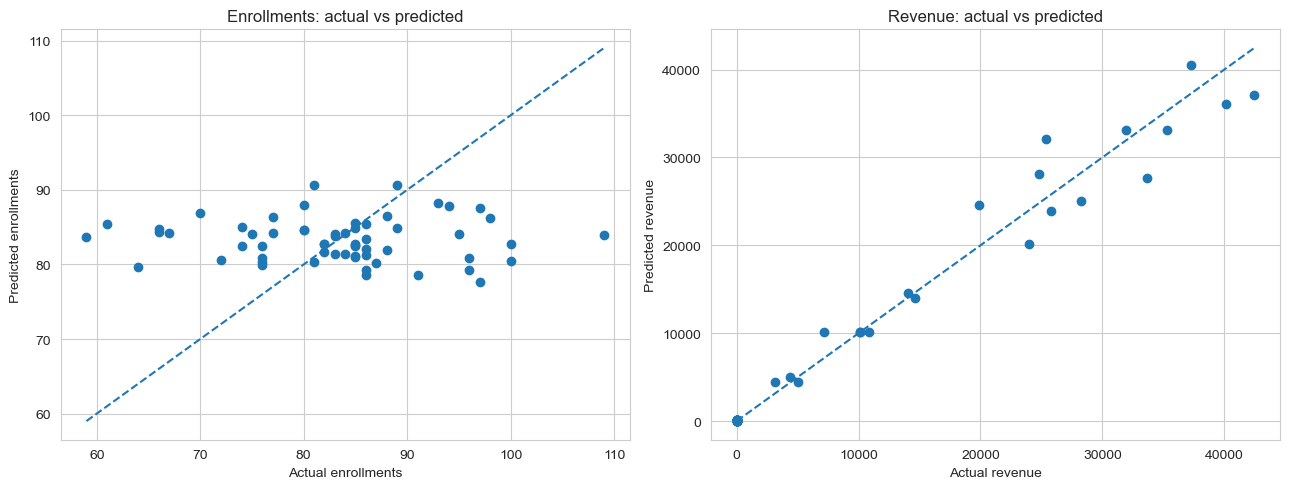

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(data["FutureEnrollments"], data["PredictedEnrollment"])
low, high = data["FutureEnrollments"].min(), data["FutureEnrollments"].max()
axes[0].plot([low, high], [low, high], "--")
axes[0].set_xlabel("Actual enrollments")
axes[0].set_ylabel("Predicted enrollments")
axes[0].set_title("Enrollments: actual vs predicted")

axes[1].scatter(data["FutureRevenue"], data["PredictedRevenue"])
high = data["FutureRevenue"].max()
axes[1].plot([0, high], [0, high], "--")
axes[1].set_xlabel("Actual revenue")
axes[1].set_ylabel("Predicted revenue")
axes[1].set_title("Revenue: actual vs predicted")

plt.tight_layout()
plt.show()

,CourseCategory,Courses,ActualEnrollments,PredictedEnrollments,ActualRevenue,PredictedRevenue
0,Artificial Intelligence,5,391,408.785134,94431.85,97794.177015
1,Business,5,405,408.537548,91170.76,85545.744351
10,Project Management,5,412,412.648040,87191.15,84905.987194
9,Programming,5,406,412.165274,40143.80,36416.988599
3,Data Science,5,452,410.689951,35883.50,34133.520705
2,Cybersecurity,5,426,419.318144,31935.06,33316.197308
5,Digital Marketing,5,382,421.776887,24835.48,24858.519772
4,Design,5,427,418.433970,19898.64,24830.664063
6,Finance,5,442,423.674077,14534.92,15361.975089
11,Web Development,5,415,410.613136,8189.03,9048.697278


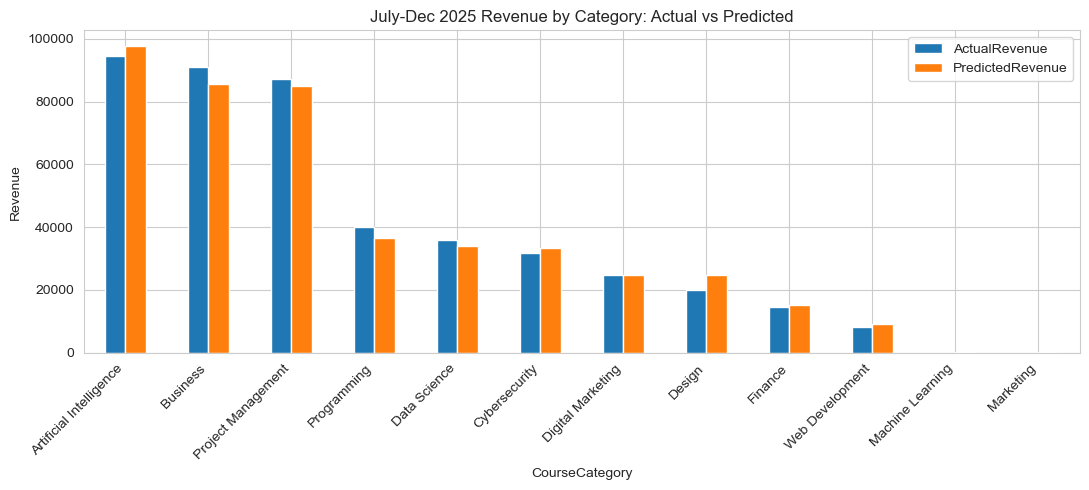

In [50]:
category = data.groupby("CourseCategory").agg(
    Courses=("CourseID", "count"),
    ActualEnrollments=("FutureEnrollments", "sum"),
    PredictedEnrollments=("PredictedEnrollment", "sum"),
    ActualRevenue=("FutureRevenue", "sum"),
    PredictedRevenue=("PredictedRevenue", "sum")
).reset_index().sort_values("ActualRevenue", ascending=False)

display(category)

category.plot(x="CourseCategory", y=["ActualRevenue", "PredictedRevenue"],
              kind="bar", figsize=(11, 5))
plt.title("July-Dec 2025 Revenue by Category: Actual vs Predicted")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [51]:

# Train the final revenue model on all available courses
final_revenue_model = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", clone(models[best_revenue_name]))
])

final_revenue_model.fit(X, y_rev)

# Save both final models
joblib.dump(
    final_model,
    "edupro_enrollment_model.pkl"
)

joblib.dump(
    final_revenue_model,
    "edupro_revenue_model.pkl"
)

# Save feature columns
joblib.dump(
    list(X.columns),
    "feature_columns.pkl"
)

# Save analysis and evaluation results
data.to_csv("model_data.csv", index=False)
results.to_csv("enrollment_model_comparison.csv", index=False)
revenue_results.to_csv("revenue_model_comparison.csv", index=False)
importance.to_csv("feature_importance.csv", index=False)
category.to_csv("category_forecast.csv", index=False)

print("Enrollment model saved.")
print("Revenue model saved.")
print("Feature columns and result files saved.")


Enrollment model saved.
Revenue model saved.
Feature columns and result files saved.
